# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
df = pd.read_csv('SAML-D.csv')

# Exploratory Data Analysis

In [3]:
df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,07-10-2022,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,07-10-2022,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,07-10-2022,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,07-10-2022,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,07-10-2022,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [4]:

# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Display the column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 4. Count normal and laundering-labelled transactions
print("\nLaundering label counts:")
print(df["Is_laundering"].value_counts())


Dataset shape: (1048575, 12)

Column names:
['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount', 'Payment_currency', 'Received_currency', 'Sender_bank_location', 'Receiver_bank_location', 'Payment_type', 'Is_laundering', 'Laundering_type']

Missing values in each column:
Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

Laundering label counts:
Is_laundering
0    1047619
1        956
Name: count, dtype: int64


In [5]:
 #understanding transaction amount

print(df['Amount'].describe())

count    1.048575e+06
mean     8.707645e+03
std      2.444582e+04
min      5.190000e+00
25%      2.114535e+03
50%      6.104870e+03
75%      1.034893e+04
max      6.213932e+06
Name: Amount, dtype: float64


In [6]:
 #Comparing normal and laundering-labelled transactions

df.groupby("Is_laundering")['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Is_laundering,,,,,,,,
0,1047619.0,8682.218377,22265.084861,5.19,2113.7700,6105.81,10349.845,999946.47
1,956.0,36571.563239,334010.895411,24.77,2821.4875,5133.36,8867.410,6213931.56


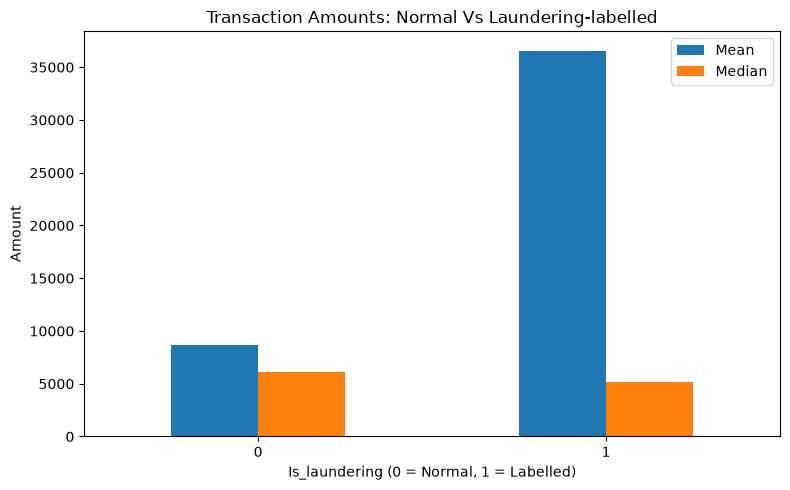

In [7]:
 #Visualizing the difference

summary = df.groupby("Is_laundering")['Amount'].agg(["mean", "median"])

summary.plot(kind = "bar", figsize = (8,5))

plt.title("Transaction Amounts: Normal Vs Laundering-labelled")
plt.xlabel("Is_laundering (0 = Normal, 1 = Labelled)")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend(["Mean", "Median"])
plt.tight_layout()
plt.show()

In [8]:
 #Analyse payment types

df["Payment_type"].value_counts()

Payment_type
ACH                222636
Credit card        222166
Cheque             221939
Debit card         221781
Cross-border       101322
Cash Withdrawal     33577
Cash Deposit        25154
Name: count, dtype: int64

In [9]:
pd.crosstab ( df["Payment_type"], df["Is_laundering"] )

Is_laundering,0,1
Payment_type,,
ACH,222519,117
Cash Deposit,25024,130
Cash Withdrawal,33455,122
Cheque,221824,115
Credit card,222033,133
Cross-border,101093,229
Debit card,221671,110


In [10]:
 #Calculating laundering rates

payment_analysis = df.groupby("Payment_type").agg(total_transactions=("Is_laundering", "count"), laundering_transactions=("Is_laundering", "sum"))

payment_analysis["laundering_rate_pct"] = (payment_analysis["laundering_transactions"] / payment_analysis["total_transactions"] * 100)

payment_analysis.sort_values("laundering_rate_pct", ascending=False).round(2)


,total_transactions,laundering_transactions,laundering_rate_pct
Payment_type,,,
Cash Deposit,25154,130,0.52
Cash Withdrawal,33577,122,0.36
Cross-border,101322,229,0.23
Credit card,222166,133,0.06
ACH,222636,117,0.05
Cheque,221939,115,0.05
Debit card,221781,110,0.05


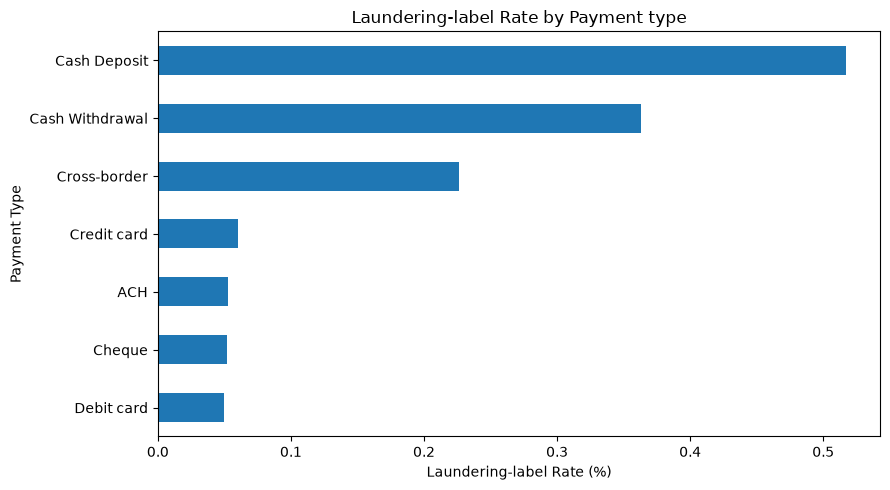

In [11]:
plot_data = payment_analysis.sort_values("laundering_rate_pct", ascending = True)

plot_data["laundering_rate_pct"].plot(kind='barh', figsize=(9,5))

plt.title("Laundering-label Rate by Payment type")
plt.xlabel("Laundering-label Rate (%)")
plt.ylabel("Payment Type")
plt.tight_layout()
plt.show()

### Finding: Payment Type Analysis

Cash Deposit had the highest laundering-label rate at 0.52%, followed by Cash Withdrawal at 0.36% and Cross-border at 0.23%.

Cross-border transactions had the largest number of laundering-labelled cases (229), despite having a lower rate than the two cash categories.

These results suggest that payment type may be a useful feature for AML risk analysis. However, payment type alone is insufficient to determine whether a transaction is suspicious. Further analysis of transaction amounts, account behavior, and other features is required.

**Limitation:** The findings describe patterns in a synthetic dataset and do not establish real-world causation or prove money laundering.

In [12]:
 #Analysing sender bank locations

df['Sender_bank_location'].value_counts()

Sender_bank_location
UK             1015115
Switzerland       2542
Japan             2416
Turkey            2338
UAE               2322
Spain             2313
USA               2102
France            1950
Nigeria           1923
India             1913
Pakistan          1906
Netherlands       1752
Morocco           1749
Austria           1698
Italy             1674
Albania           1664
Mexico            1628
Germany           1570
Name: count, dtype: int64

In [13]:
 #Laundering rate by sender location

sender_analysis = df.groupby("Sender_bank_location").agg(total_transactions=("Is_laundering", "count"), laundering_transactions=("Is_laundering", "sum"))

sender_analysis["laundering_rate_pct"] = (sender_analysis["laundering_transactions"] / sender_analysis["total_transactions"] * 100)

sender_analysis.sort_values("laundering_rate_pct", ascending=False).round(2)

,total_transactions,laundering_transactions,laundering_rate_pct
Sender_bank_location,,,
Switzerland,2542,9,0.35
Mexico,1628,4,0.25
Austria,1698,3,0.18
UAE,2322,4,0.17
Japan,2416,4,0.17
India,1913,3,0.16
Nigeria,1923,3,0.16
France,1950,3,0.15
Spain,2313,3,0.13


In [14]:
 #Analysing receiver bank locations

receiver_analysis = df.groupby("Receiver_bank_location").agg(
    total_transactions=("Is_laundering", "count"),
    laundering_transactions=("Is_laundering", "sum")
)

receiver_analysis["laundering_rate_pct"] = (
    receiver_analysis["laundering_transactions"]
    / receiver_analysis["total_transactions"]
    * 100
)

receiver_analysis.sort_values(
    "laundering_rate_pct",
    ascending=False
).round(2)

,total_transactions,laundering_transactions,laundering_rate_pct
Receiver_bank_location,,,
Nigeria,5022,46,0.92
Turkey,3408,22,0.65
Italy,3638,20,0.55
Albania,4877,26,0.53
Austria,3722,19,0.51
UAE,4043,16,0.40
Pakistan,3576,13,0.36
Morocco,4462,13,0.29
France,4368,12,0.27


### Finding: Geographic Transaction Analysis

Sender and receiver bank locations showed different laundering-label
patterns. Switzerland had the highest observed sender-location rate
(0.35%), while Nigeria had the highest receiver-location rate
(approximately 0.92%).

The UK accounted for the largest number of laundering-labelled
transactions in both summaries, reflecting its very large transaction
volume.

These findings describe the synthetic dataset only. Location alone
should not be used to classify a transaction as suspicious. Further
analysis of sender–receiver routes and other transaction features is
required.

In [15]:
 #Analysing sender-receiver routes

route_analysis = df.groupby(
    ["Sender_bank_location", "Receiver_bank_location"]
).agg(
    total_transactions=("Is_laundering", "count"),
    laundering_transactions=("Is_laundering", "sum")
).reset_index()

route_analysis["laundering_rate_pct"] = (
    route_analysis["laundering_transactions"]
    / route_analysis["total_transactions"]
    * 100
)

# Keep routes with at least 100 transactions
reliable_routes = route_analysis[
    route_analysis["total_transactions"] >= 100
].copy()

reliable_routes.sort_values(
    ["laundering_rate_pct", "laundering_transactions"],
    ascending=False
).round(2).head(15)

,Sender_bank_location,Receiver_bank_location,total_transactions,laundering_transactions,laundering_rate_pct
254,UK,Nigeria,4834,45,0.93
258,UK,Turkey,3329,21,0.63
244,UK,Albania,4515,24,0.53
245,UK,Austria,3600,19,0.53
249,UK,Italy,3488,16,0.46
259,UK,UAE,3922,16,0.41
255,UK,Pakistan,3445,13,0.38
211,Switzerland,UK,2256,8,0.35
252,UK,Morocco,4297,13,0.30
246,UK,France,4167,12,0.29


### Finding: Sender–Receiver Route Analysis

The UK → Nigeria route had the highest laundering-label rate among the 15 displayed routes, at approximately 0.93% (45 labelled transactions out of 4,834). The UK → Turkey route followed at approximately 0.63% (21 out of 3,329).

Several other UK-originating routes, including UK → Albania and UK → Austria, also showed elevated rates relative to the overall dataset.

These findings suggest that sender–receiver location pairs may provide useful context for AML risk analysis. However, most transactions on even the highest-rate route were not labelled as laundering.

**Limitations:** The results are descriptive patterns from a synthetic dataset. Route-level rates alone do not establish suspicious activity, and rules developed using these same labels must be evaluated carefully to avoid overly optimistic results.


<Figure size 900x500 with 0 Axes>

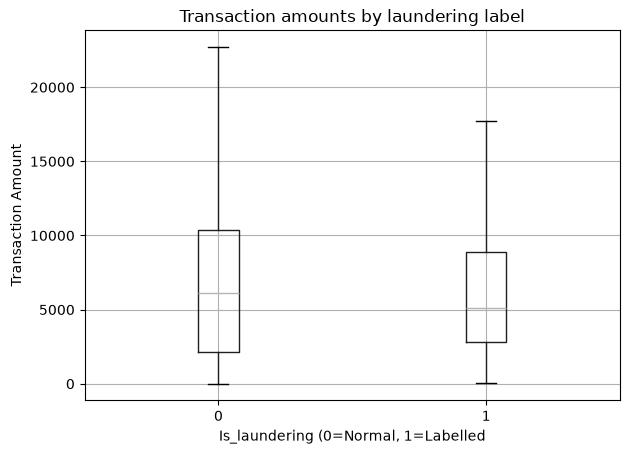

In [16]:
 #Examining transaction amounts by laundering label using a box plot

plt.figure(figsize=(9,5))

df.boxplot(column="Amount", by="Is_laundering", showfliers=False)

plt.title("Transaction amounts by laundering label")
plt.suptitle("")
plt.xlabel("Is_laundering (0=Normal, 1=Labelled")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

In [17]:
df.groupby("Is_laundering")["Amount"].quantile(
    [0.50, 0.90, 0.95, 0.99]
).unstack().round(2)

,0.50,0.90,0.95,0.99
Is_laundering,,,,
0,6105.81,16274.92,21537.86,43872.16
1,5133.36,17143.74,36400.02,403253.23


In [18]:
 #Building AML detection rule

threshold = 43872.1594

df["amount_rule_flag"] = (
    df["Amount"] > threshold
).astype(int)

print(confusion_matrix(
    df["Is_laundering"],
    df["amount_rule_flag"]
))

print(classification_report(
    df["Is_laundering"],
    df["amount_rule_flag"],
    target_names=["Normal", "Laundering-labelled"],
    zero_division=0
))

[[1037142   10477]
 [    911      45]]
                     precision    recall  f1-score   support

             Normal       1.00      0.99      0.99   1047619
Laundering-labelled       0.00      0.05      0.01       956

           accuracy                           0.99   1048575
          macro avg       0.50      0.52      0.50   1048575
       weighted avg       1.00      0.99      0.99   1048575



In [19]:
 #Create the flags

df["amount_rule_flag"] = (df["Amount"] > 43872.16).astype(int)

In [20]:
df[["Amount", "Is_laundering", "amount_rule_flag"]].head(5)

,Amount,Is_laundering,amount_rule_flag
0,1459.15,0,0
1,6019.64,0,0
2,14328.44,0,0
3,11895.00,0,0
4,115.25,0,0


In [21]:
df["amount_rule_flag"].value_counts()

amount_rule_flag
0    1038053
1      10522
Name: count, dtype: int64

In [22]:
df.loc[
    df["amount_rule_flag"] == 1,
    "Is_laundering"
].value_counts()

Is_laundering
0    10477
1       45
Name: count, dtype: int64

In [23]:
df.loc[
    df["amount_rule_flag"] == 0,
    "Is_laundering"
].value_counts()

Is_laundering
0    1037142
1        911
Name: count, dtype: int64

In [24]:
 #calculating recall

true_positives = (
    (df["Is_laundering"] == 1) &
    (df["amount_rule_flag"] == 1)
).sum()

false_negatives = (
    (df["Is_laundering"] == 1) &
    (df["amount_rule_flag"] == 0)
).sum()

recall = true_positives / (
    true_positives + false_negatives
)

print("True Positives:", true_positives)
print("False Negatives:", false_negatives)
print("Recall:", round(recall * 100, 2), "%")

True Positives: 45
False Negatives: 911
Recall: 4.71 %


In [25]:
 #Building 2nd AML Flag detection rule

df["amount_rule_20000"] = (df["Amount"]>20000).astype(int)

df["amount_rule_20000"].value_counts()

amount_rule_20000
0    984924
1     63651
Name: count, dtype: int64

In [26]:
 #Calculating Precision & Recall

true_positives_20000 = ((df["Is_laundering"]==1) & (df["amount_rule_20000"]==1)).sum()

print("True Positives: ", true_positives_20000)

True Positives:  82


In [27]:
precision_20000 = (
    true_positives_20000 /
    df["amount_rule_20000"].sum()
)

print("Precision:", round(precision_20000 * 100, 2), "%")

Precision: 0.13 %


In [28]:
 #Confusion Matrix

pd.crosstab(
    df["Is_laundering"],
    df["amount_rule_flag"],
    rownames=["Actual"],
    colnames=["Predicted"]
)

Predicted,0,1
Actual,,
0,1037142,10477
1,911,45


In [29]:
 #Confusion Matrix

pd.crosstab(
    df["Is_laundering"],
    df["amount_rule_20000"],
    rownames=["Actual"],
    colnames=["Predicted"]
)

Predicted,0,1
Actual,,
0,984050,63569
1,874,82


In [30]:
 #Calculating F1-score

precision_original = 45 / 10522
recall_original = 45 / 956

f1_original = (
    2 * precision_original * recall_original
    / (precision_original + recall_original)
)

precision_20000 = 82 / 63651
recall_20000 = 82 / 956

f1_20000 = (
    2 * precision_20000 * recall_20000
    / (precision_20000 + recall_20000)
)

print("Original rule F1-score:", round(f1_original * 100, 2), "%")
print("20,000 threshold F1-score:", round(f1_20000 * 100, 2), "%")

Original rule F1-score: 0.78 %
20,000 threshold F1-score: 0.25 %
